# FUSegNet · Memahami baseline pertama
**CHECKPOINT 1 — REPRODUKSI & ANALISIS HASIL**

Chronic Wound · `cp1-baseline-01` · 26 Oktober 2026

Notebook ini menjawab tiga pertanyaan: **seberapa baik model bekerja, di mana ia gagal,
dan apa yang layak diteliti berikutnya?** Semua hasil berasal dari checkpoint terpilih
**epoch 52**, dengan threshold **0.5**. Menjalankan notebook hanya membaca artefak lokal;
training dan pemilihan checkpoint sudah selesai.

**Alur baca:** [protokol](#protokol) → [kurva belajar](#kurva-belajar) →
[hasil akhir](#hasil-akhir) → [analisis error](#analisis-error) →
[prediksi](#prediksi) → [keterbatasan](#keterbatasan) → [kesimpulan](#kesimpulan).

> **Langsung lihat hasil:** notebook ini dipublikasikan dengan seluruh output yang sudah
> dieksekusi, termasuk tabel, grafik, foto contoh, ground truth, prediksi, dan overlay error.
> Buka di GitHub atau VS Code/Jupyter tanpa menjalankan ulang cell untuk melihat hasilnya.

## 0 · Setup & pemeriksaan bukti

Gunakan kernel **FUSeg · Analysis** (`.venv-analysis`). Inference sebelumnya memakai
`.venv-training` yang sama dengan training. Pemisahan environment menjaga versi model tetap konsisten.
Pemeriksaan berikut mencocokkan checkpoint, konfigurasi, split, source training, data,
**402 mask prediksi**, hitungan TP/TN/FP/FN, serta seluruh metrik akhir.
Jika artefak berubah atau belum tersedia, proses berhenti dengan error.

In [1]:
from pathlib import Path
import sys
import json
import importlib.metadata as metadata

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/baseline.json").is_file() and (p / "scripts/cp1_analysis.py").is_file())
sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from cp1_analysis import (
    configure_style, load_analysis, summarize, metric_table, paper_comparison,
    category_table, empty_table, overlap_table, learning_curves, final_metrics_plot,
    distribution_plot, size_plot, empty_plot, select_examples, prediction_gallery, export_tables,
)

%matplotlib inline
configure_style()
ctx = load_analysis("cp1-baseline-01")
validation, test = ctx["frames"]["validation"], ctx["frames"]["test"]

def show_table(frame, formats=None):
    display(HTML(frame.to_html(index=False, border=0, classes="cp1-table",
                               float_format=lambda x: f"{x:.2f}", formatters=formats or {})))

display(HTML('''<style>
  .cp1-table {border-collapse:collapse; font-size:14px; margin:14px 0;}
  .cp1-table th {background:#18324B; color:white; padding:10px 14px; text-align:left;}
  .cp1-table td {padding:9px 14px; border-bottom:1px solid #E7EDF2;}
  .cp1-table tr:nth-child(even) {background:#F4F8FA;}
</style>'''))
print(f"✓ {ctx['verified_masks']} mask cocok dengan evaluasi akhir; source, data, dan checkpoint terverifikasi.")
print("✓ Notebook ini tidak menjalankan training, mengubah threshold, atau memilih ulang checkpoint.")

✓ 402 mask cocok dengan evaluasi akhir; source, data, dan checkpoint terverifikasi.
✓ Notebook ini tidak menjalankan training, mengubah threshold, atau memilih ulang checkpoint.


In [2]:
data_dice = ctx["summaries"]["test"]["data_based"]["dice"] * 100
image_dice = ctx["summaries"]["test"]["image_based"]["dice"] * 100
display(HTML(f'''
<div style="background:#18324B;color:white;padding:24px;border-radius:12px;margin:12px 0;">
  <div style="font-size:12px;letter-spacing:2px;color:#9FD9D0;">BASELINE · HASIL TEST LOKAL</div>
  <div style="font-size:32px;font-weight:700;margin:8px 0;">{data_dice:.2f}% Dice</div>
  <div>Data-based · Image-based {image_dice:.2f}% · 278 gambar</div>
  <div style="margin-top:14px;color:#D8E6EF;">82 epoch selesai &nbsp; | &nbsp; Checkpoint 52
    &nbsp; | &nbsp; Seed 42 &nbsp; | &nbsp; Offline HARD_LINE</div>
</div>'''))

<a id="protokol"></a>
## 1 · Apa tepatnya yang direproduksi?

Kita menjalankan **implementasi publik FUSegNet**: EfficientNet-B7 pretrained ImageNet,
decoder P-scSE, augmentasi, loss, dan aturan checkpoint penulis. Wrapper proyek menyimpan
split, seed, checkpoint, dan hasil secara reproducible.

Ini satu model baseline **FUSegNet pada Chronic Wound**, sedangkan **x-FUSegNet** pada
FUSeg Challenge memakai ensemble lima model. Hasil di notebook ini bukan skor challenge.

In [3]:
protocol = pd.DataFrame([
    ("Data lokal", "831 source train + 278 source test; input 224 × 224"),
    ("Split aktual", "707 train / 124 validation / 278 test; manifest disimpan"),
    ("Random seed", "42; seed training penulis tidak diketahui"),
    ("Training", "Batch 2; Adam lr 1e-4; scheduler turun sampai 1e-5"),
    ("Durasi", f"{ctx['status']['seconds'] / 60:.2f} menit pada A100 80 GB"),
    ("Pemilihan checkpoint", "Aturan penulis: perbaikan loss, elif IoU; epoch 52"),
    ("Early stopping", "Berhenti epoch 82, 30 epoch tanpa checkpoint baru"),
    ("Mask prediksi", "Probabilitas ≥ 0.5; threshold tidak dituning pada test"),
    ("Metrik utama", "Offline HARD_LINE; data-based dan image-based dipisahkan"),
], columns=["Komponen", "Pengaturan"])
show_table(protocol)

Komponen,Pengaturan
Data lokal,831 source train + 278 source test; input 224 × 224
Split aktual,707 train / 124 validation / 278 test; manifest disimpan
Random seed,42; seed training penulis tidak diketahui
Training,Batch 2; Adam lr 1e-4; scheduler turun sampai 1e-5
Durasi,105.36 menit pada A100 80 GB
Pemilihan checkpoint,"Aturan penulis: perbaikan loss, elif IoU; epoch 52"
Early stopping,"Berhenti epoch 82, 30 epoch tanpa checkpoint baru"
Mask prediksi,Probabilitas ≥ 0.5; threshold tidak dituning pada test
Metrik utama,Offline HARD_LINE; data-based dan image-based dipisahkan


**Batas kesetaraan dengan paper:** paper menyebut 810 train / 200 test, sedangkan arsip
publik berisi 831 / 278. Pembagian train/validation asli tidak tersedia; evaluator untuk
tabel utama paper belum dapat dipastikan. Duplikasi bawaan dataset dipertahankan dan
diaudit pada bagian 7. Karena itu, kedekatan angka tidak membuktikan protokol identik.

Detail: [audit implementasi](../docs/reference-audit.md),
[protokol benchmark](../docs/benchmark.md), [catatan run](../reports/cp1-baseline-01.md).

<a id="kurva-belajar"></a>
## 2 · Bagaimana model belajar?

Loss dan F-score berikut berasal dari log training asli. Garis putus-putus menunjukkan
checkpoint yang benar-benar dipakai untuk evaluasi akhir.

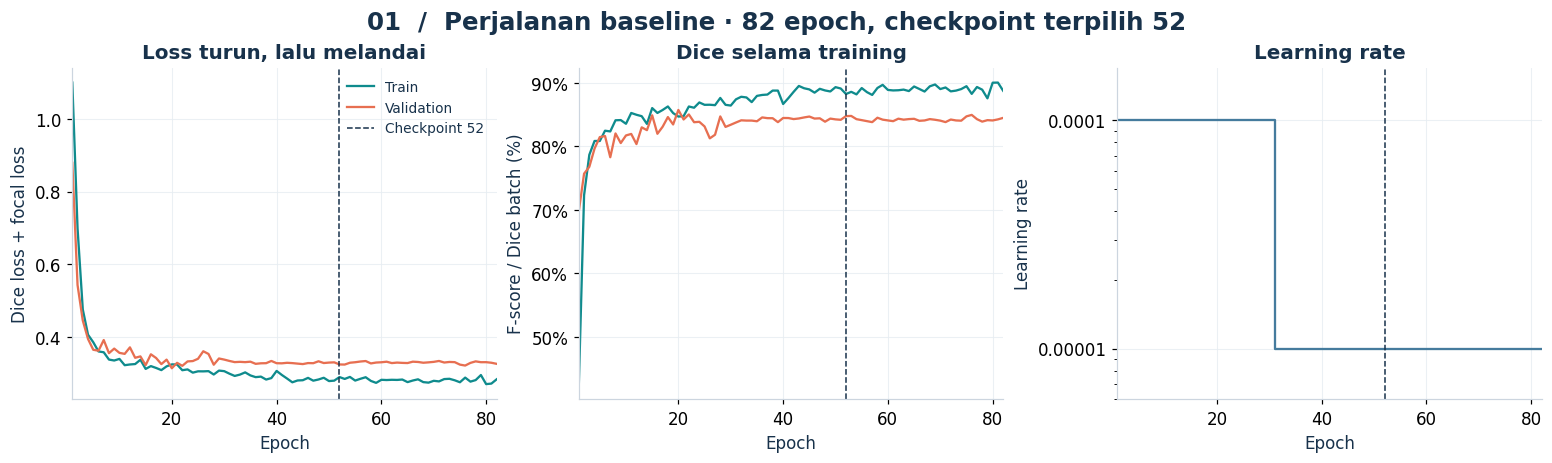

In [4]:
learning_curves(ctx)
plt.show()

In [5]:
history = ctx["history"]
peak = max(history, key=lambda row: row["validation"]["fscore"])
selected = next(row for row in history if row["epoch"] == ctx["status"]["selected_epoch"])
display(Markdown(
    f"**Cara membaca:** loss turun cepat pada awal training, kemudian melandai. "
    f"Puncak validation F-score di log ada pada **epoch {peak['epoch']} "
    f"({peak['validation']['fscore'] * 100:.2f}%)**, tetapi aturan checkpoint penulis memilih "
    f"**epoch {selected['epoch']}**. Aturan tersebut memakai loss/IoU, bukan maksimum Dice. "
    "Kita mempertahankannya untuk CP1.\n\n"
    "F-score di kurva adalah **rata-rata batch dengan smoothing** dari runner penulis. "
    "Metrik akhir di bawah memakai agregasi piksel/per gambar dan kebijakan GT kosong. "
    "Angka kurva dan evaluasi akhir karena itu tidak harus sama."
))

**Cara membaca:** loss turun cepat pada awal training, kemudian melandai. Puncak validation F-score di log ada pada **epoch 20 (85.73%)**, tetapi aturan checkpoint penulis memilih **epoch 52**. Aturan tersebut memakai loss/IoU, bukan maksimum Dice. Kita mempertahankannya untuk CP1.

F-score di kurva adalah **rata-rata batch dengan smoothing** dari runner penulis. Metrik akhir di bawah memakai agregasi piksel/per gambar dan kebijakan GT kosong. Angka kurva dan evaluasi akhir karena itu tidak harus sama.

<a id="hasil-akhir"></a>
## 3 · Hasil akhir dan perbandingan referensi

Untuk satu gambar, **Dice = 2TP / (2TP + FP + FN)**. TP adalah piksel luka yang benar
terdeteksi, FP adalah piksel background yang diprediksi luka, dan FN adalah luka yang terlewat.

- **Data-based:** jumlahkan TP, FP, FN semua gambar, lalu hitung skor. Gambar dengan
  banyak piksel luka berkontribusi lebih besar pada Dice.
- **Image-based:** hitung skor setiap gambar, lalu rata-ratakan. Setiap gambar berbobot sama.

Pada **GT kosong**, evaluator per gambar memberi skor 1 jika prediksi juga kosong,
dan 0 jika ada prediksi luka. Kasus ini dianalisis tersendiri pada bagian 5.

Agregasi,Metrik,Validation,Test
Data-based,Dice,85.90%,92.29%
Data-based,Iou,75.29%,85.68%
Data-based,Precision,81.63%,93.47%
Data-based,Recall,90.65%,91.13%
Image-based,Dice,82.34%,86.42%
Image-based,Iou,75.27%,80.01%
Image-based,Precision,83.63%,88.17%
Image-based,Recall,83.78%,86.81%


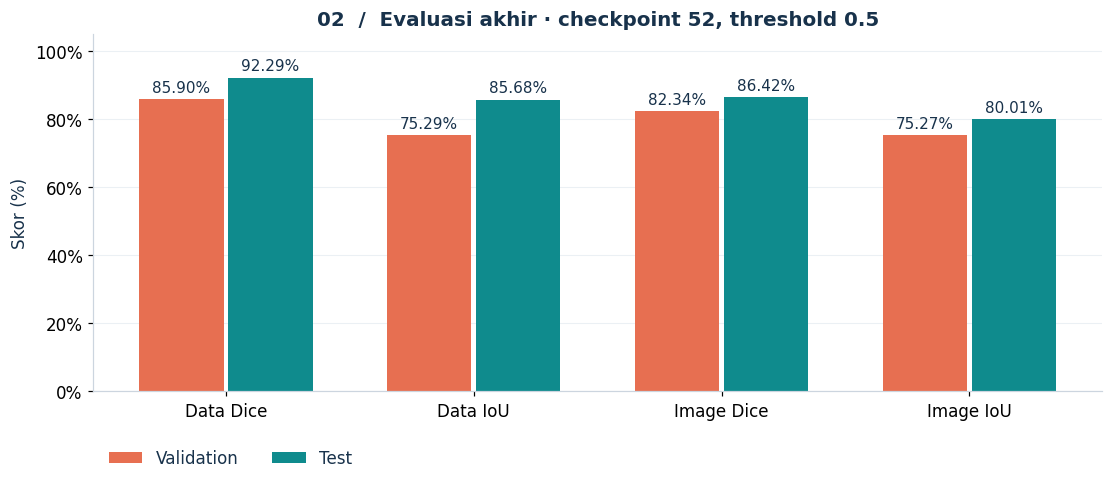

In [6]:
show_table(metric_table(ctx), {"Validation": lambda x: f"{x:.2f}%", "Test": lambda x: f"{x:.2f}%"})
final_metrics_plot(ctx)
plt.show()

### Angka paper sebagai titik referensi

Selisih ditulis dalam **percentage points (pp)**. Nilai paper diambil dari hasil
Chronic Wound FUSegNet, bukan ensemble FUSeg Challenge.

In [7]:
show_table(paper_comparison(ctx), {"Selisih (pp)": lambda x: f"{x:+.2f}"})
display(Markdown(
    "Angka lokal dekat dengan referensi paper, tetapi **bukan perbandingan dengan protokol identik**. "
    "Perbedaan jumlah data, split asli yang belum tersedia, evaluator, dan duplikasi "
    "membatasi interpretasi selisih ini. Satu run juga belum mengukur variasi antar-seed."
))

Dice,Paper (%),Run ini (%),Selisih (pp)
Data-based,92.70,92.29,-0.41
Image-based,86.05,86.42,+0.37


Angka lokal dekat dengan referensi paper, tetapi **bukan perbandingan dengan protokol identik**. Perbedaan jumlah data, split asli yang belum tersedia, evaluator, dan duplikasi membatasi interpretasi selisih ini. Satu run juga belum mengukur variasi antar-seed.

In [8]:
primary = ctx["evaluations"]["test"]["offline_hard_line"]["data_based"]["dice"] * 100
legacy = ctx["evaluations"]["test"]["author_inline_legacy"]["data_based"]["dice"] * 100
display(Markdown(
    f"**Mengapa evaluator harus disebutkan?** Prediksi yang sama menghasilkan "
    f"**{primary:.2f}%** data-based Dice pada evaluator offline dan **{legacy:.2f}%** "
    "pada evaluator inline lama. Implementasi inline menghitung seluruh piksel, termasuk "
    "background, sebagai TP saat sebuah mask cocok sempurna. Notebook memakai hasil "
    "**offline** sebagai hasil utama; skor legacy hanya dicatat untuk menjelaskan audit."
))

**Mengapa evaluator harus disebutkan?** Prediksi yang sama menghasilkan **92.29%** data-based Dice pada evaluator offline dan **96.66%** pada evaluator inline lama. Implementasi inline menghitung seluruh piksel, termasuk background, sebagai TP saat sebuah mask cocok sempurna. Notebook memakai hasil **offline** sebagai hasil utama; skor legacy hanya dicatat untuk menjelaskan audit.

<a id="analisis-error"></a>
## 4 · Di mana model masih kesulitan?

### 4.1 · Sebaran Dice per gambar

Grafik ini hanya memuat gambar dengan **GT berisi luka** agar skor 0/1 dari GT kosong
tidak mengaburkan sebaran segmentasi. Tabel hasil utama tetap memakai seluruh gambar.

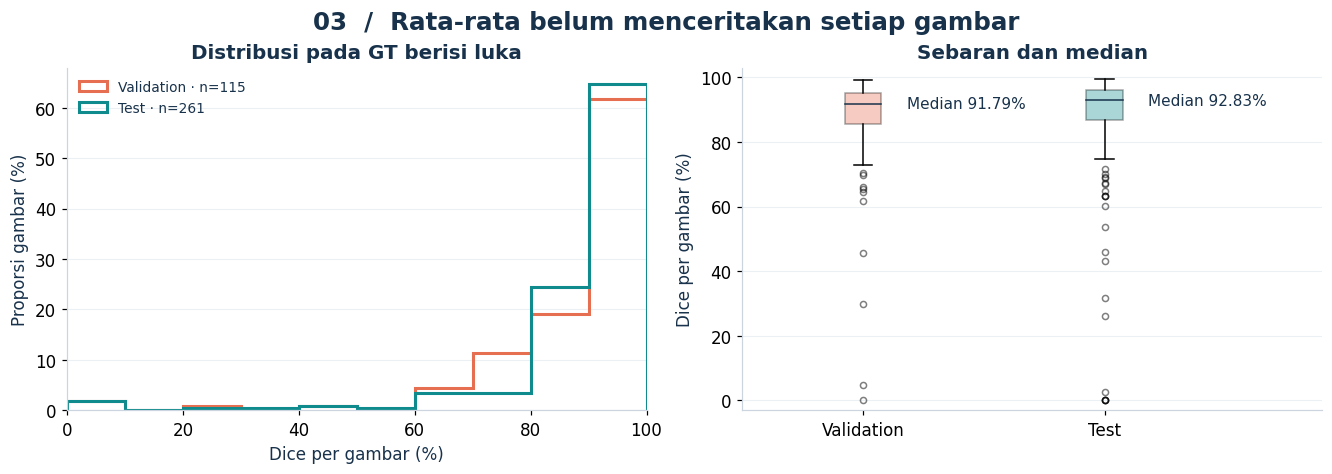

Split,GT berisi luka,Mean Dice (%),Median Dice (%),Luka terlewat seluruhnya (TP=0)
Validation,115,87.04,91.79,1
Test,261,88.22,92.83,4


In [9]:
distribution_plot(ctx)
plt.show()
positive_summary = []
for split, frame in ctx["frames"].items():
    positive = frame[frame.gt_pixels.gt(0)]
    positive_summary.append({
        "Split": split.title(), "GT berisi luka": len(positive),
        "Mean Dice (%)": positive.dice.mean() * 100,
        "Median Dice (%)": positive.dice.median() * 100,
        "Luka terlewat seluruhnya (TP=0)": int(positive.tp.eq(0).sum()),
    })
show_table(pd.DataFrame(positive_summary))

### 4.2 · Hubungan dengan ukuran luka

Luas dihitung dari **jumlah piksel GT / seluruh kanvas 224 × 224, termasuk padding hitam**,
bukan ukuran luka dalam cm². Nilai ini juga dipengaruhi skala/crop foto sumber.
C0–C9 mengikuti keanggotaan `categorized_oldDfu.json` penulis. Rentang luas pada tabel
dihitung ulang dari mask aktual; C0 berisi GT kosong dan dibahas terpisah.

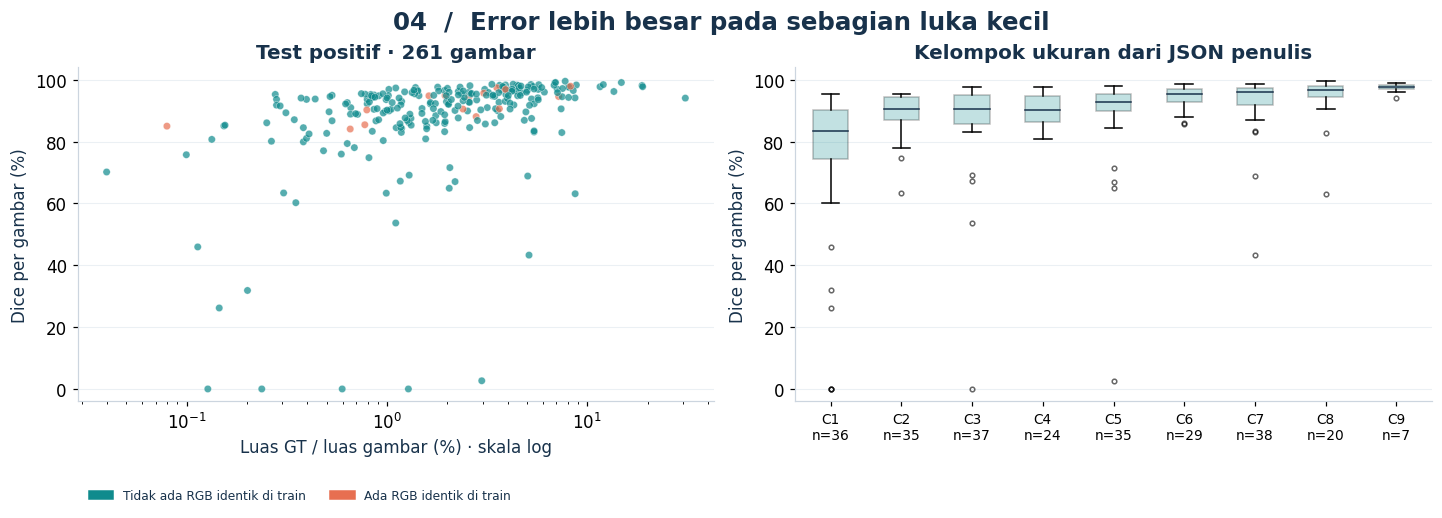

Kategori,n,Luas min (%),Luas max (%),Mean Dice (%),Median Dice (%),Data Dice (%)
C0,17,0.00,0.00,58.82,100.00,0.00
C1,36,0.04,0.60,73.22,83.60,77.88
C2,35,0.62,0.99,89.07,90.67,88.68
C3,37,1.00,1.50,86.50,90.46,87.22
C4,24,1.56,1.98,90.12,90.20,90.35
C5,35,2.00,2.97,88.34,92.85,88.10
C6,29,3.04,4.00,94.39,95.25,94.42
C7,38,4.02,5.92,92.46,95.93,92.91
C8,20,6.11,8.82,94.21,96.74,94.54
C9,7,11.59,30.88,97.36,97.77,96.97


**Temuan deskriptif:** C1 (n=36; luas GT 0.04–0.60%) memiliki mean Dice **73.22%**, sedangkan C9 (n=7) **97.36%**. Hasil ini mendukung pemeriksaan error pada luka kecil. Ukuran sampel tidak seimbang dan faktor gambar lain belum dikontrol, sehingga hubungan ini belum membuktikan penyebab error.

In [10]:
size_plot(ctx)
plt.show()
categories = category_table(ctx)
show_table(categories)
c1 = categories.loc[categories.Kategori.eq("C1")].iloc[0]
c9 = categories.loc[categories.Kategori.eq("C9")].iloc[0]
display(Markdown(
    f"**Temuan deskriptif:** C1 (n={int(c1['n'])}; luas GT "
    f"{c1['Luas min (%)']:.2f}–{c1['Luas max (%)']:.2f}%) memiliki mean Dice "
    f"**{c1['Mean Dice (%)']:.2f}%**, sedangkan C9 (n={int(c9['n'])}) "
    f"**{c9['Mean Dice (%)']:.2f}%**. Hasil ini mendukung pemeriksaan error pada luka kecil. "
    "Ukuran sampel tidak seimbang dan faktor gambar lain belum dikontrol, sehingga "
    "hubungan ini belum membuktikan penyebab error."
))

## 5 · Gambar dengan ground truth kosong

**GT kosong** berarti anotasi tidak berisi piksel luka. Ini bukan diagnosis kondisi pasien.
Menurut HARD_LINE, satu piksel FP saja membuat Dice per gambar menjadi 0; sebab itu
kita tampilkan juga besar area FP agar tingkat error tidak disamaratakan.

Split,GT kosong,Benar kosong,Ada false positive,FP terbesar (piksel)
Validation,9,2,7,10141
Test,17,10,7,1229


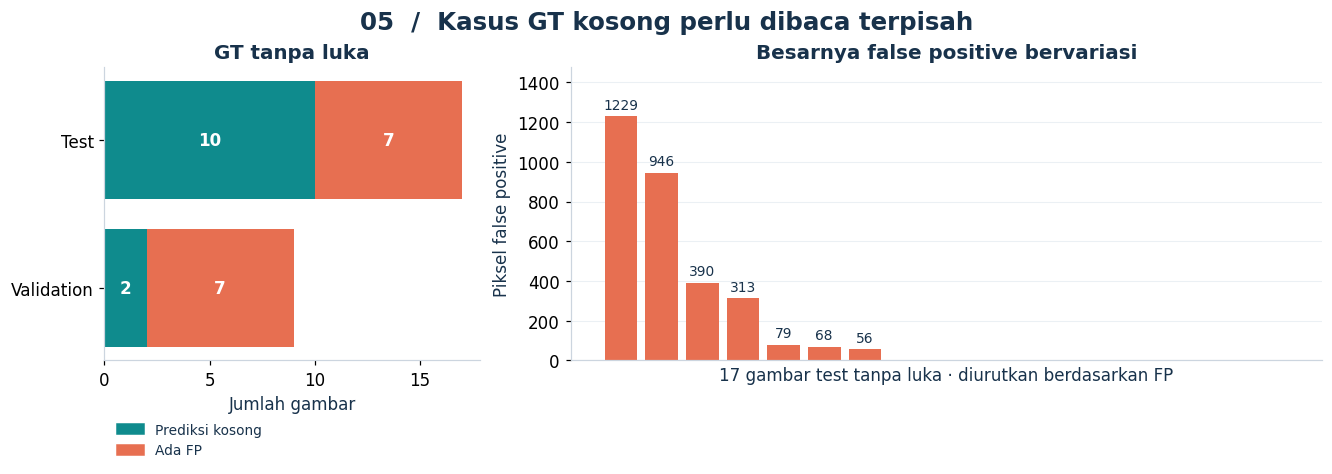

Pada test, **10/17** gambar GT kosong diprediksi kosong. **7/17** menghasilkan FP (41.2% pada subset ini), dengan **56–1,229 piksel FP** per gambar bermasalah. Proporsi tersebut memakai jumlah gambar GT kosong sebagai denominator, bukan seluruh gambar test.

In [11]:
show_table(empty_table(ctx))
empty_plot(ctx)
plt.show()
no_wound = test[test.gt_pixels.eq(0)]
fp_sizes = no_wound.loc[no_wound.fp.gt(0), "fp"]
display(Markdown(
    f"Pada test, **{int(no_wound.fp.eq(0).sum())}/{len(no_wound)}** gambar GT kosong "
    f"diprediksi kosong. **{len(fp_sizes)}/{len(no_wound)}** menghasilkan FP "
    f"({len(fp_sizes) / len(no_wound) * 100:.1f}% pada subset ini), dengan "
    f"**{int(fp_sizes.min()):,}–{int(fp_sizes.max()):,} piksel FP** per gambar bermasalah. "
    "Proporsi tersebut memakai jumlah gambar GT kosong sebagai denominator, bukan seluruh gambar test."
))

<a id="prediksi"></a>
## 6 · Seperti apa prediksinya?

Setiap baris menampilkan **gambar asli → ground truth → prediksi → overlay error**.
Mask putih berarti luka. Overlay memakai **hijau = TP**, **merah = FP**, **biru = FN**;
background asli tetap terlihat. Semua panel memakai checkpoint dan threshold yang sama.

**Zoom untuk keterbacaan:** file sumber memiliki padding hitam yang besar. Semua kolom
pada satu baris menampilkan crop yang sama, mencakup seluruh foto nonhitam serta seluruh
piksel GT/prediksi, dengan margin 4 piksel. Hanya tampilan yang di-zoom; mask, metrik, dan
persentase luas tetap dihitung pada kanvas penuh 224 × 224. Proporsi gambar dipertahankan.

**Aturan pemilihan:** sampel acak diambil terlebih dahulu memakai seed 42 dari foto test
positif yang unik secara piksel RGB. Galeri berikutnya mengambil Dice tertinggi,
terdekat median, dan terendah dari foto yang belum dipilih; tiap galeri berisi tiga contoh.
Tie Dice terendah diurutkan berdasarkan GT terbesar lalu nama file; tie lainnya berdasarkan
nama file. Galeri GT kosong memuat satu benar kosong dan dua FP terbesar.
Daftar lengkap disimpan di `tables/selected_examples.csv`.

Galeri ekstrem adalah **contoh terpilih**, bukan estimasi frekuensi kegagalan.
Foto yang sama tidak diulang antar-galeri. Analisis ini tidak menentukan ulang model atau threshold.

In [12]:
examples = select_examples(ctx)
show_table(examples.groupby("selection", sort=False).size().rename("Jumlah contoh").reset_index())
print("15 foto unik; nama file, aturan pemilihan, dan skor tersimpan untuk pelacakan.")

selection,Jumlah contoh
best,3
median,3
worst,3
random,3
empty_correct,1
empty_fp,2


15 foto unik; nama file, aturan pemilihan, dan skor tersimpan untuk pelacakan.


### 6.1 · Prediksi dengan Dice tertinggi

Perhatikan kesesuaian mask dan sisa error di sekeliling area GT.

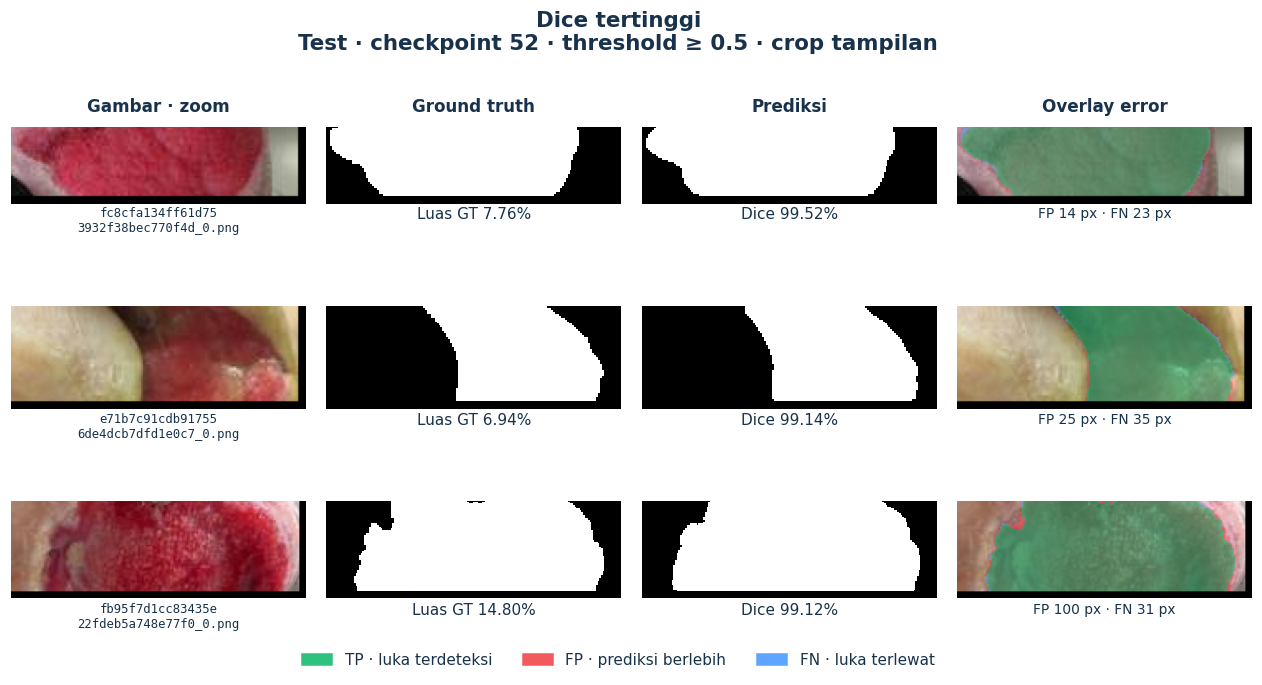

In [13]:
prediction_gallery(ctx, "best")
plt.show()

### 6.2 · Prediksi di sekitar median

Contoh ini lebih dekat ke bagian tengah distribusi Dice pada gambar test berisi luka.

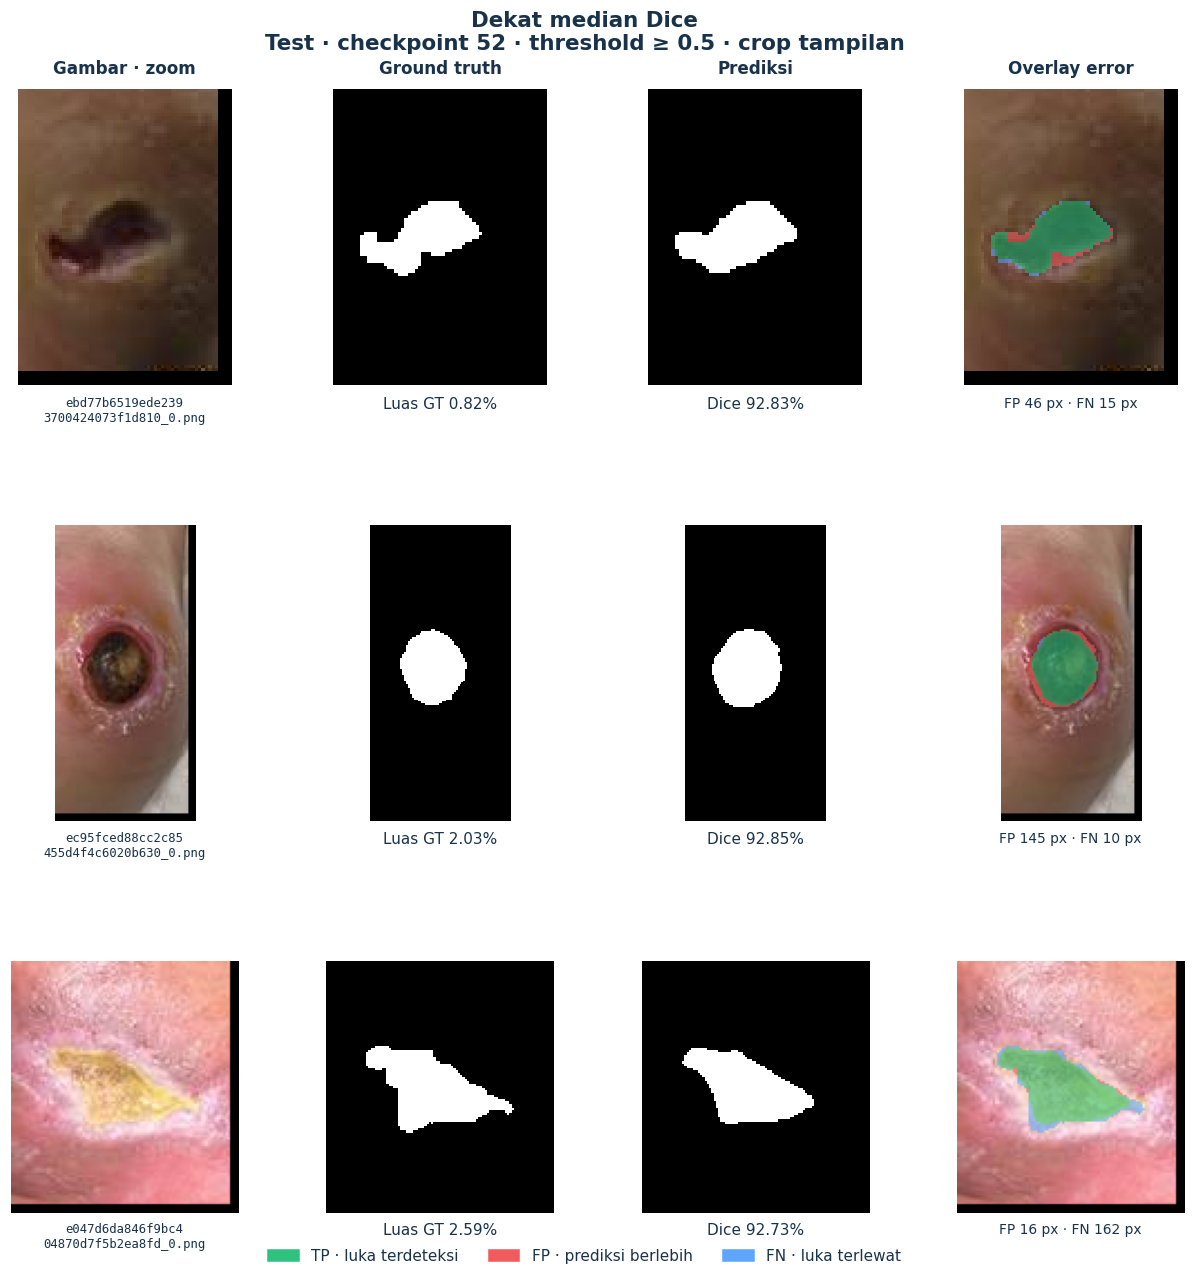

In [14]:
prediction_gallery(ctx, "median")
plt.show()

### 6.3 · Prediksi dengan Dice terendah

Ini contoh luka yang terlewat seluruhnya: GT berisi luka, sementara prediksi kosong.
Tiga panel ini dipilih dari kasus terburuk; jumlah keseluruhan kasus TP=0 ada pada bagian 4.1.

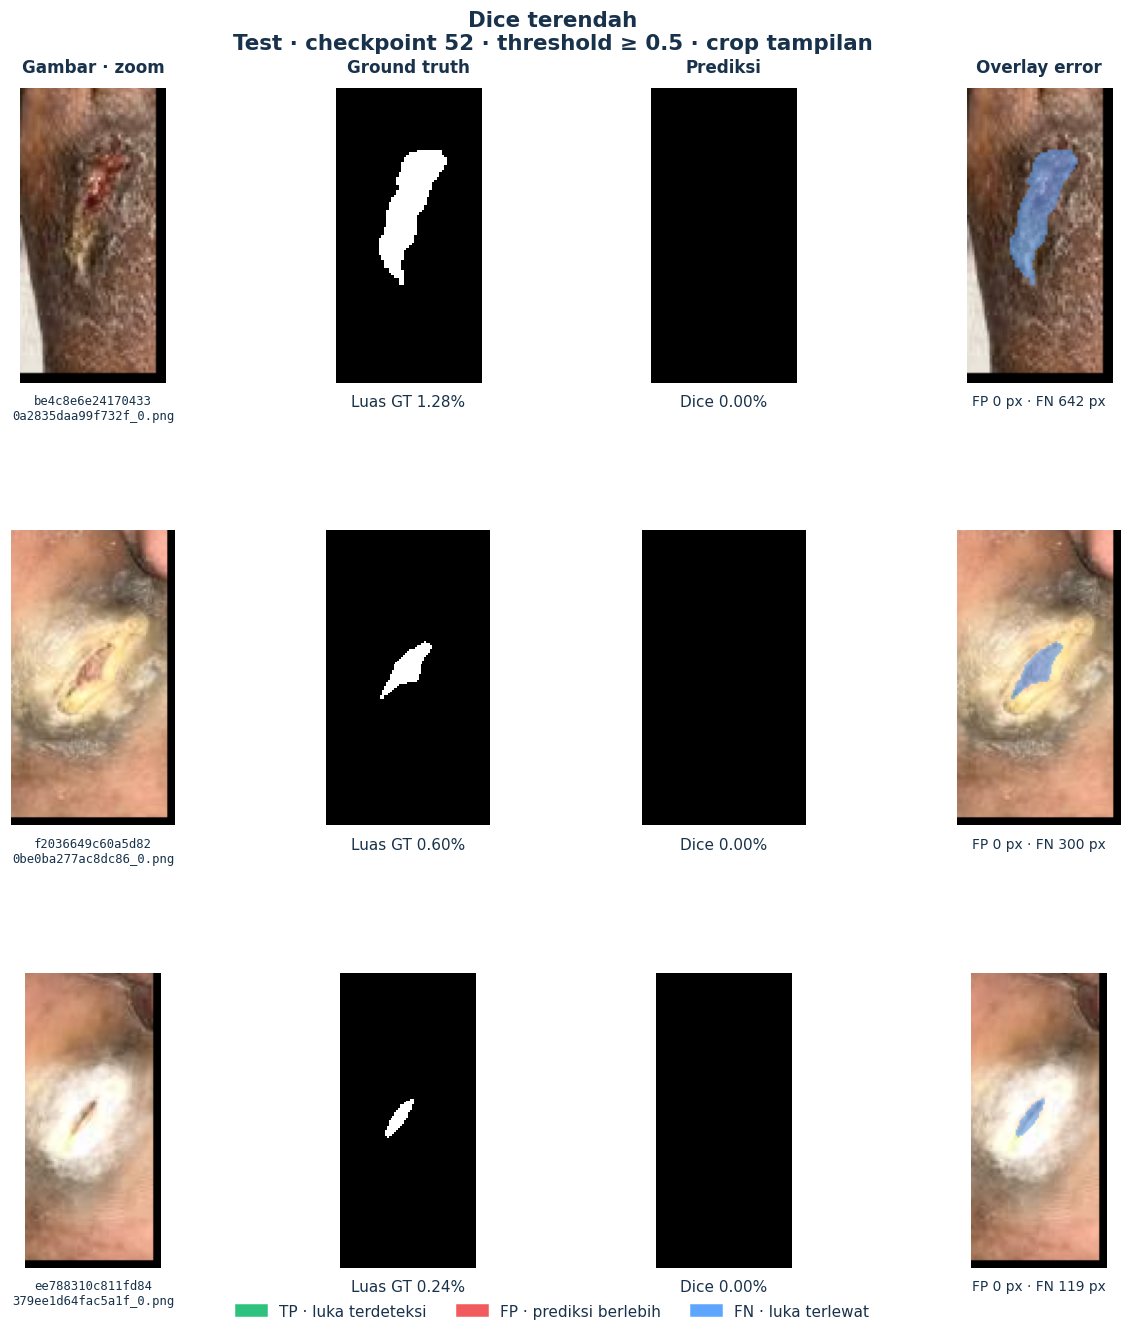

In [15]:
prediction_gallery(ctx, "worst")
plt.show()

### 6.4 · Sampel acak yang reproducible

Sampel acak melengkapi galeri best/worst agar interpretasi tidak hanya bertumpu pada ekstrem.
Tiga gambar masih terlalu sedikit untuk menyimpulkan karakteristik seluruh dataset.

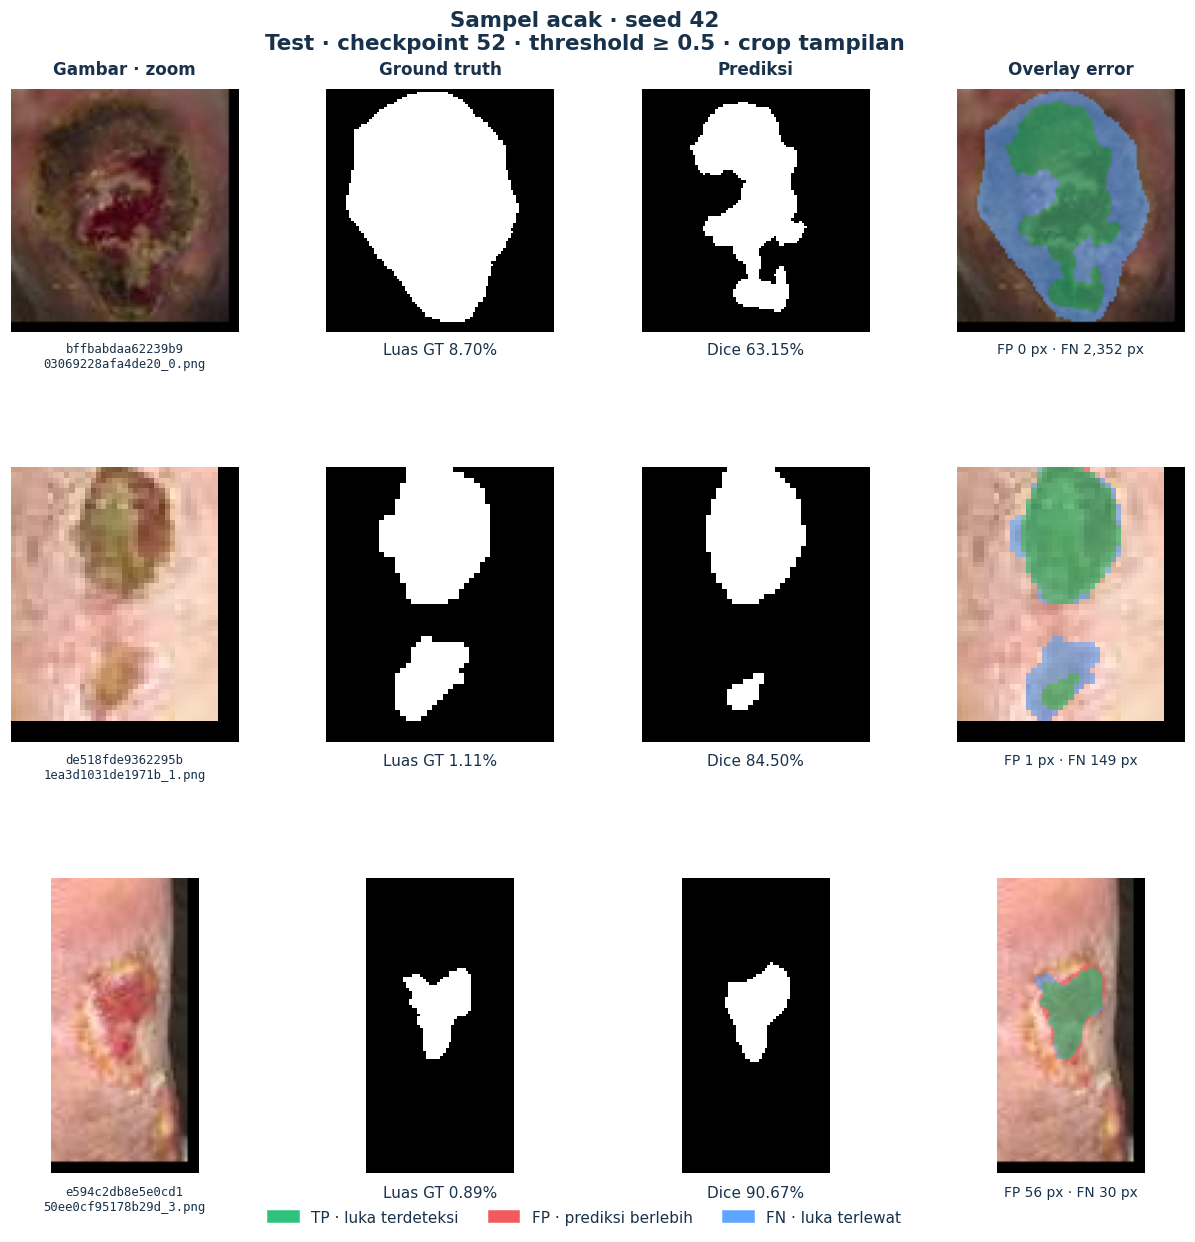

In [16]:
prediction_gallery(ctx, "random")
plt.show()

### 6.5 · GT kosong: benar kosong dan false positive

Mask GT kosong dapat menghasilkan skor sempurna maupun nol, bergantung pada ada tidaknya FP.
Lihat kolom prediksi dan angka FP untuk membedakannya.

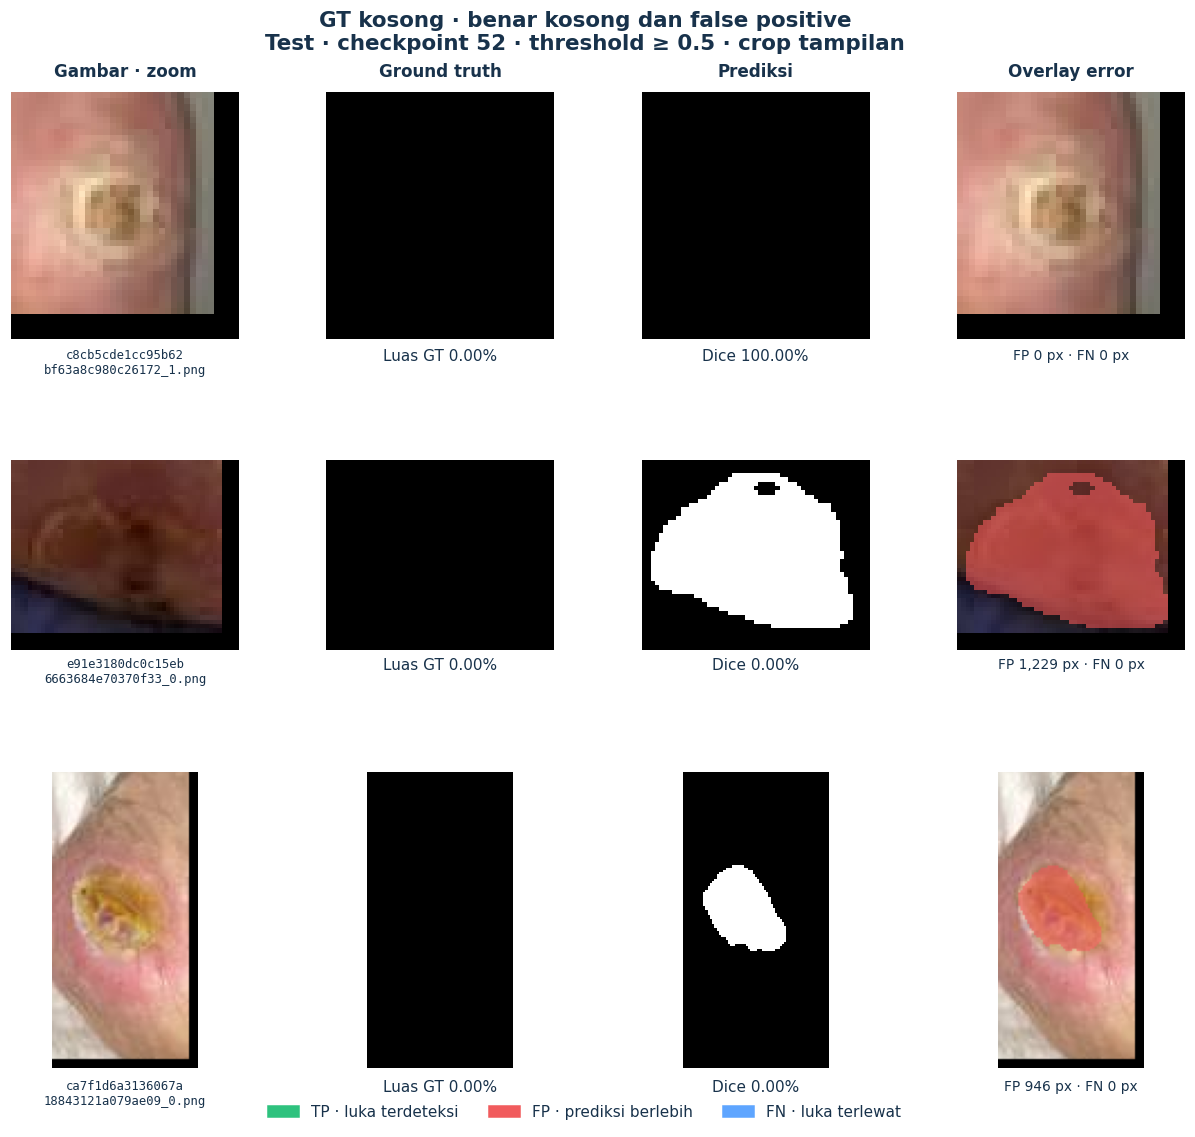

In [17]:
prediction_gallery(ctx, "empty")
plt.show()

<a id="keterbatasan"></a>
## 7 · Audit overlap dan batas interpretasi

Audit berikut membandingkan **hash seluruh piksel RGB** dengan 707 gambar train aktual.
Ini mendeteksi foto yang benar-benar identik, termasuk file dengan encoding berbeda.
Tidak ada retraining, penghapusan data, atau perubahan split pada analisis ini.

In [18]:
overlaps = overlap_table(ctx)
show_table(overlaps)
overlap_test = int(test.overlap_train.sum())
overlap_val = int(validation.overlap_train.sum())
display(Markdown(
    f"Ada **{overlap_val} gambar validation** dan **{overlap_test} gambar test** "
    "yang identik secara piksel RGB dengan suatu gambar train aktual. "
    "Metrik subset di atas hanya pembacaan ulang prediksi yang sama. "
    "Subset tanpa kecocokan RGB **belum menjamin pemisahan pasien**; foto lain dari pasien "
    "atau luka yang sama tidak dapat disingkirkan oleh pemeriksaan ini. "
    "Hasil utama mempertahankan source split dan harus dibaca bersama keterbatasan tersebut."
))

Split,Piksel RGB sama dengan train,n,Data Dice (%),Image Dice (%)
Validation,Ya,2,95.89,95.65
Validation,Tidak,122,85.73,82.12
Test,Ya,16,94.33,92.55
Test,Tidak,262,92.17,86.05


Ada **2 gambar validation** dan **16 gambar test** yang identik secara piksel RGB dengan suatu gambar train aktual. Metrik subset di atas hanya pembacaan ulang prediksi yang sama. Subset tanpa kecocokan RGB **belum menjamin pemisahan pasien**; foto lain dari pasien atau luka yang sama tidak dapat disingkirkan oleh pemeriksaan ini. Hasil utama mempertahankan source split dan harus dibaca bersama keterbatasan tersebut.

Batas lain yang perlu dibawa ke presentasi:

- **Satu run, satu seed:** belum ada ukuran variasi antar-training atau klaim signifikansi.
- **Protokol paper belum identik:** jumlah data berbeda; split asli dan evaluator tabel paper belum pasti.
- **Mask biner:** analisis menilai anotasi luka/background, tanpa label jaringan, diagnosis, atau derajat keparahan.
- **Test sudah dianalisis:** temuan test di sini bersifat deskriptif. Pilih dan tune eksperimen CP2
  melalui validation; bila pengembangan mengikuti temuan test, nyatakan bahwa test ini tidak lagi
  menjadi evaluasi baru yang sepenuhnya tidak tersentuh.

<a id="kesimpulan"></a>
## 8 · Apa yang bisa kita sampaikan pada CP1?

In [19]:
missed = int(test.loc[test.gt_pixels.gt(0), "tp"].eq(0).sum())
display(Markdown(f'''
1. **Baseline berjalan sampai selesai.** Implementasi publik FUSegNet dilatih 82 epoch;
   checkpoint 52 dipilih oleh aturan penulis, lalu dievaluasi pada 278 gambar test.
2. **Hasil lokal:** data-based Dice **{data_dice:.2f}%**, image-based Dice **{image_dice:.2f}%**.
   Angkanya dekat referensi paper, dengan keterbatasan protokol yang sudah dicatat.
3. **Error yang terukur:** mean Dice pada kelompok luka terkecil C1 **{c1['Mean Dice (%)']:.2f}%**;
   **{missed} gambar berisi luka** mempunyai TP=0; **{len(fp_sizes)} dari {len(no_wound)}** GT kosong menghasilkan FP.
4. **Keterbatasan penting:** {overlap_test} gambar test identik secara RGB dengan train;
   pemisahan pasien belum terverifikasi dan variasi antar-seed belum diukur.

**Hipotesis untuk CP2, belum terbukti:** pendekatan yang memberi perhatian lebih pada luka kecil
atau mengurangi prediksi pada background layak diuji. Ablasi loss/attention atau penanganan
ketidakseimbangan harus dirancang sebagai eksperimen baru dengan validation dan protokol tetap.
Temuan ini belum menunjukkan metode mana yang akan memperbaiki hasil.

**Untuk CP1:** training, evaluasi, analisis awal, dan visualisasi sudah tersedia.
Berikutnya susun laporan serta slide yang memuat protokol, hasil, contoh error, dan keterbatasan.
'''))


1. **Baseline berjalan sampai selesai.** Implementasi publik FUSegNet dilatih 82 epoch;
   checkpoint 52 dipilih oleh aturan penulis, lalu dievaluasi pada 278 gambar test.
2. **Hasil lokal:** data-based Dice **92.29%**, image-based Dice **86.42%**.
   Angkanya dekat referensi paper, dengan keterbatasan protokol yang sudah dicatat.
3. **Error yang terukur:** mean Dice pada kelompok luka terkecil C1 **73.22%**;
   **4 gambar berisi luka** mempunyai TP=0; **7 dari 17** GT kosong menghasilkan FP.
4. **Keterbatasan penting:** 16 gambar test identik secara RGB dengan train;
   pemisahan pasien belum terverifikasi dan variasi antar-seed belum diukur.

**Hipotesis untuk CP2, belum terbukti:** pendekatan yang memberi perhatian lebih pada luka kecil
atau mengurangi prediksi pada background layak diuji. Ablasi loss/attention atau penanganan
ketidakseimbangan harus dirancang sebagai eksperimen baru dengan validation dan protokol tetap.
Temuan ini belum menunjukkan metode mana yang akan memperbaiki hasil.

**Untuk CP1:** training, evaluasi, analisis awal, dan visualisasi sudah tersedia.
Berikutnya susun laporan serta slide yang memuat protokol, hasil, contoh error, dan keterbatasan.


## 9 · Artefak siap pakai & reproduksibilitas

Gambar agregat diekspor dalam **PNG 300 dpi + SVG**. Panel prediksi diekspor sebagai PNG.
Seluruh ekspor berada di folder `outputs/` lokal. Notebook ini dapat dijalankan ulang dari cache
mask tanpa GPU; bila cache belum ada, ikuti [petunjuk notebook](README.md) untuk inference sekali.

In [20]:
exported_tables = export_tables(ctx)
figure_files = sorted(ctx["figures"].glob("*.png"))
print(f"Figur: {len(figure_files)} PNG, {len(list(ctx['figures'].glob('*.svg')))} SVG")
print(f"Folder: {ctx['figures'].relative_to(ROOT)}/")
print(f"Tabel: {ctx['tables'].relative_to(ROOT)}/")
print(f"Ringkasan: {(ctx['output'] / 'analysis-summary.json').relative_to(ROOT)}")
for path in figure_files:
    print(f"  • {path.name}")

Figur: 10 PNG, 5 SVG
Folder: outputs/analysis/cp1-baseline-01/figures/
Tabel: outputs/analysis/cp1-baseline-01/tables/
Ringkasan: outputs/analysis/cp1-baseline-01/analysis-summary.json
  • 01_learning_curves.png
  • 02_final_metrics.png
  • 03_dice_distribution.png
  • 04_wound_size.png
  • 05_empty_masks.png
  • 06_predictions_best.png
  • 06_predictions_empty.png
  • 06_predictions_median.png
  • 06_predictions_random.png
  • 06_predictions_worst.png


In [21]:
versions = pd.DataFrame([
    {"Komponen": "Python analysis", "Versi": sys.version.split()[0]},
    *[{"Komponen": f"{name} (analysis)", "Versi": metadata.version(name)}
      for name in ["numpy", "pandas", "matplotlib", "Pillow", "nbclient", "ipykernel"]],
    {"Komponen": "PyTorch (training/inference)", "Versi": ctx["environment"]["packages"]["torch"]},
    {"Komponen": "torchvision (training/inference)", "Versi": ctx["environment"]["packages"]["torchvision"]},
])
show_table(versions)
print("Author revision:", ctx["config"]["reference_revision"])
print("Pipeline training commit:", ctx["environment"]["git_revision"])
print("Config fingerprint:", ctx["export"]["identity"]["config_fingerprint"])
print("Split fingerprint:", ctx["export"]["identity"]["split_fingerprint"])
print("Checkpoint SHA256:", ctx["export"]["identity"]["checkpoint_sha256"])

Komponen,Versi
Python analysis,3.10.4
numpy (analysis),1.24.1
pandas (analysis),1.5.3
matplotlib (analysis),3.7.5
Pillow (analysis),9.4.0
nbclient (analysis),0.10.2
ipykernel (analysis),6.29.5
PyTorch (training/inference),1.11.0+cu113
torchvision (training/inference),0.12.0+cu113


Author revision: 60e8cfe0c8e2dacffa55fe208b8abb6815f7f6cc
Pipeline training commit: e7c312fcc2db46db34978b7ce3926ef1effb232e
Config fingerprint: 86ee03891cb5da1bda31efcba4332b52f345f5a8ae8057b1fb600e6e11dcbc8b
Split fingerprint: 7937d6b039db4eedf736dd0482a6379917fd9640d39d03c2c5fdac5047166925
Checkpoint SHA256: 5d7cf8cd011c1681d853ff1306b293774fa770a217cf7f29f0223e8498d1a999


**Referensi dan jejak bukti**

- Dhar et al. (2023), [FUSegNet: A Deep Convolutional Neural Network for Foot Ulcer Segmentation](https://arxiv.org/abs/2305.02961v2).
- [Kode penulis](https://github.com/mrinal054/FUSegNet), dipin pada revision yang tercetak di atas;
  keanggotaan kategori berasal dari `categorized_oldDfu.json` dalam snapshot itu.
- [Sumber dataset publik](https://github.com/uwm-bigdata/wound-segmentation),
  dipin pada commit `42a272dfe0679f20675e826385925cb7562934b6`; [audit data lokal](../docs/datasets.md).
- Bukti angka lokal: `outputs/runs/cp1-baseline-01/{history,validation,evaluation-test}.json`
  dan CSV per gambar; cache prediksi diverifikasi terhadap artefak tersebut pada bagian 0.